# Sales Prediction using Python
**CodeAlpha Data Science Internship – Task 4**

**Goal:** predict product sales from advertising spend on three platforms (TV, Radio, Newspaper), understand **how changes in each channel affect sales**, and turn that into practical budget advice.

**Workflow:** cleaning → EDA → feature selection → feature engineering → model comparison (repeated CV) → hold-out test → diagnostics → impact & budget analysis → saved model.

> The file has 200 markets. As in the standard version of this dataset, spend is in **thousands of dollars** and sales in **thousands of units** (units are not stated in the file). There is **no date column**, so this is a cross-sectional regression problem, not a time-series forecast; "future sales" here means sales for a planned spend mix.

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import OLSInfluence
from scipy import stats
from pathlib import Path
import joblib

from sklearn.model_selection import train_test_split, KFold, RepeatedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
IMG = Path("images"); IMG.mkdir(exist_ok=True)
def save(n): plt.savefig(IMG / f"{n}.png", bbox_inches="tight", dpi=150)
SEED = 42

## 2. Load and clean

In [2]:
raw = pd.read_csv("data/Advertising.csv")
print(raw.shape); display(raw.head())

(200, 5)


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [3]:
df = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")]).copy()   # drop the saved row-index column
df.columns = df.columns.str.strip()
print("Missing values :", int(df.isna().sum().sum()))
print("Duplicate rows :", int(df.duplicated().sum()))
print("Zero values    :", (df == 0).sum().to_dict())
df.describe().round(2)

Missing values : 0
Duplicate rows : 0
Zero values    : {'TV': 0, 'Radio': 1, 'Newspaper': 0, 'Sales': 0}


,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


The data is clean: no missing values or duplicates; the only cleaning needed was dropping the leftover index column (`Unnamed: 0`). A few `Radio = 0` rows are legitimate (no radio spend in that market). `Newspaper` has a long right tail (max 114).

## 3. Exploratory analysis

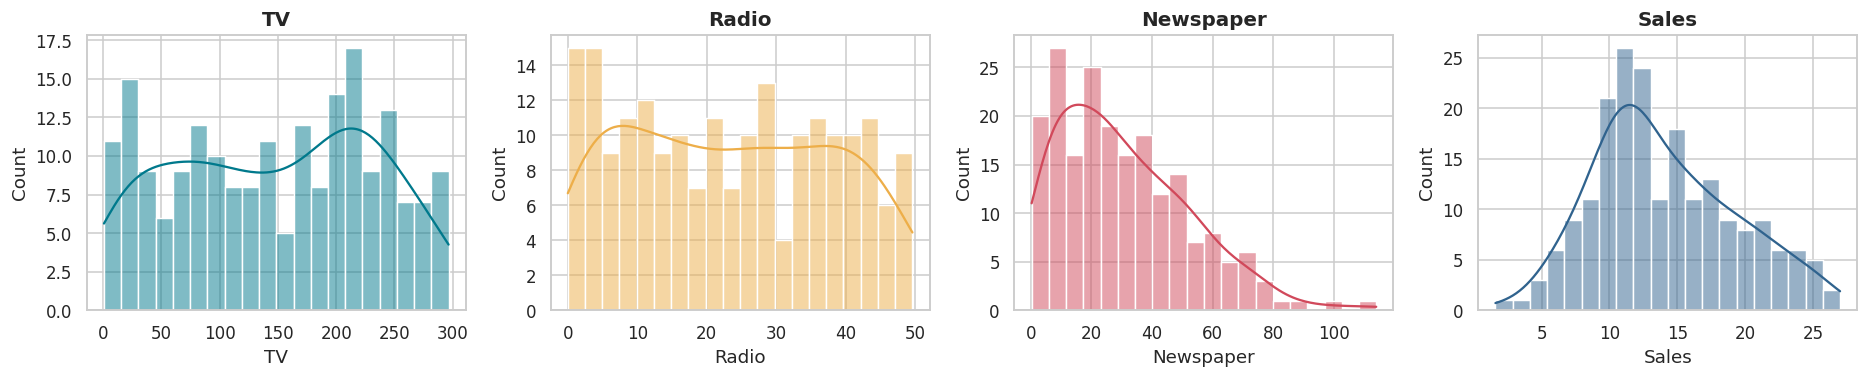

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, c, col in zip(ax, ["TV", "Radio", "Newspaper", "Sales"], ["#00798c", "#edae49", "#d1495b", "#30638e"]):
    sns.histplot(df[c], bins=20, kde=True, ax=a, color=col); a.set_title(c)
plt.tight_layout(); save("01_distributions"); plt.show()

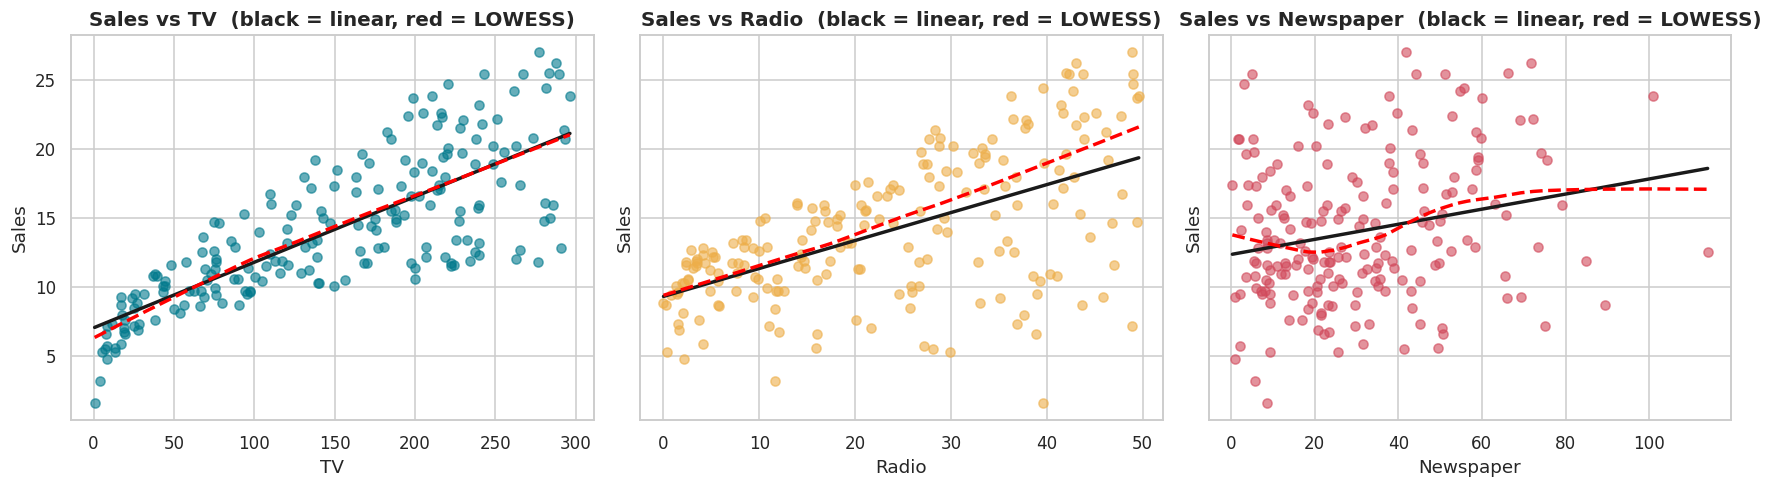

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for a, c, col in zip(ax, ["TV", "Radio", "Newspaper"], ["#00798c", "#edae49", "#d1495b"]):
    sns.regplot(data=df, x=c, y="Sales", ax=a, color=col, scatter_kws={"alpha": .6}, line_kws={"color": "k"}, ci=None)
    sns.regplot(data=df, x=c, y="Sales", ax=a, scatter=False, lowess=True, line_kws={"color": "red", "ls": "--"})
    a.set_title(f"Sales vs {c}  (black = linear, red = LOWESS)")
plt.tight_layout(); save("02_sales_vs_channels"); plt.show()

TV has the strongest and clearest relationship but it **flattens at high spend** (the LOWESS curve bends below the straight line): diminishing returns. Radio is positive, and Newspaper looks only weakly related with a lot of scatter.

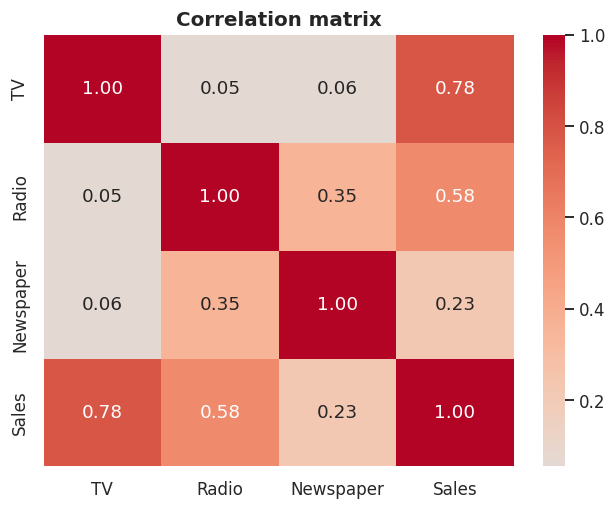

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax); ax.set_title("Correlation matrix")
plt.tight_layout(); save("03_correlation"); plt.show()

`Newspaper` is correlated with `Radio` (0.35) and with sales (0.23). That raises a question: does newspaper spend really matter, or does it just move together with radio?

## 4. Feature selection

In [7]:
simple = smf.ols("Sales ~ Newspaper", df).fit()
multi  = smf.ols("Sales ~ TV + Radio + Newspaper", df).fit()
print("Newspaper alone  : coef = %.4f, p = %.2g" % (simple.params["Newspaper"], simple.pvalues["Newspaper"]))
print("Newspaper with TV+Radio: coef = %.4f, p = %.2f" % (multi.params["Newspaper"], multi.pvalues["Newspaper"]))
multi.summary2().tables[1].round(4)

Newspaper alone  : coef = 0.0547, p = 0.0011
Newspaper with TV+Radio: coef = -0.0010, p = 0.86


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
Intercept,2.9389,0.3119,9.4223,0.0000,2.3238,3.5540
TV,0.0458,0.0014,32.8086,0.0000,0.0430,0.0485
Radio,0.1885,0.0086,21.8935,0.0000,0.1715,0.2055
Newspaper,-0.0010,0.0059,-0.1767,0.8599,-0.0126,0.0105


On its own, newspaper looks useful (significant positive slope). Once TV and Radio are in the model, its effect falls to ~0 (p ≈ 0.86): newspaper spend was just correlated with radio spend. Cross-validation and LASSO agree:

In [8]:
CV = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)
SC = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}
def cv_table(spec, cv=CV, data=df):
    rows = {}
    for name, (est, cols) in spec.items():
        s = cross_validate(est, data[cols], data["Sales"], cv=cv, scoring=SC, n_jobs=-1)
        rows[name] = {"R2": s["test_r2"].mean(), "R2 std": s["test_r2"].std(),
                      "MAE": -s["test_mae"].mean(), "RMSE": -s["test_rmse"].mean()}
    return pd.DataFrame(rows).T.round(3)

cv_table({"Linear: TV + Radio + Newspaper": (LinearRegression(), ["TV", "Radio", "Newspaper"]),
          "Linear: TV + Radio":              (LinearRegression(), ["TV", "Radio"])})

,R2,R2 std,MAE,RMSE
Linear: TV + Radio + Newspaper,0.884,0.046,1.291,1.704
Linear: TV + Radio,0.886,0.044,1.282,1.690


In [9]:
lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=SEED)).fit(df[["TV", "Radio", "Newspaper"]], df["Sales"])
pd.Series(lasso[-1].coef_, index=["TV", "Radio", "Newspaper"]).round(3).to_frame("LASSO coef (standardised)")

,LASSO coef (standardised)
TV,3.823
Radio,2.689
Newspaper,0.000


Dropping Newspaper does not hurt accuracy at all, and LASSO shrinks it to (almost) zero. **Newspaper is removed from the model.**

## 5. Feature engineering: diminishing returns and channel synergy
Two patterns are visible: (1) TV saturates, and (2) TV and Radio may **reinforce each other**. A simple check is to plot sales against TV separately for low / medium / high radio spend.

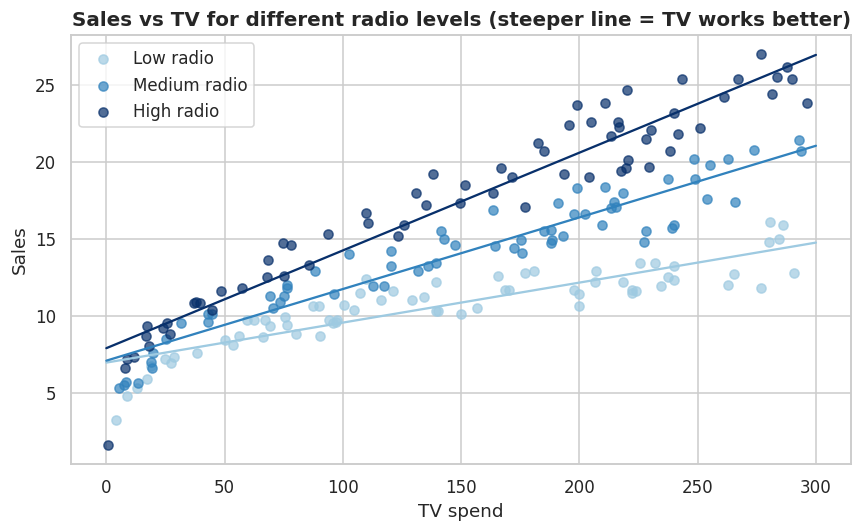

In [10]:
df["RadioLevel"] = pd.qcut(df["Radio"], 3, labels=["Low radio", "Medium radio", "High radio"])
fig, ax = plt.subplots(figsize=(8, 5))
for lvl, c in zip(["Low radio", "Medium radio", "High radio"], ["#9ecae1", "#3182bd", "#08306b"]):
    d = df[df.RadioLevel == lvl]
    ax.scatter(d.TV, d.Sales, alpha=.7, color=c, label=lvl)
    z = np.polyfit(d.TV, d.Sales, 1); xs = np.linspace(0, 300, 50); ax.plot(xs, np.polyval(z, xs), color=c)
ax.set(title="Sales vs TV for different radio levels (steeper line = TV works better)", xlabel="TV spend", ylabel="Sales"); ax.legend()
plt.tight_layout(); save("04_synergy"); plt.show()
df = df.drop(columns="RadioLevel")

The lines get **steeper as radio increases**: TV advertising is more effective when radio spend is also high. A plain additive model cannot express this, so I add an interaction term (`TV x Radio`) and a curvature term (`TV²`), i.e. a degree-2 polynomial on TV and Radio.

## 6. Modelling
* **Evaluation:** 80/20 hold-out split plus 5-fold x 10-repeat cross-validation (n = 200 is small, so a single split is noisy).
* **Metrics:** R², MAE and RMSE (in thousands of units).
* **Candidates:** a linear baseline, then progressively richer regressions, plus tree ensembles for comparison.

In [11]:
poly2 = lambda: Pipeline([("poly", PolynomialFeatures(2, include_bias=False)), ("lr", LinearRegression())])
poly3 = lambda: make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 30)))
spec = {
 "1. Linear (TV, Radio, Newspaper) [baseline]": (LinearRegression(), ["TV", "Radio", "Newspaper"]),
 "2. Linear (TV, Radio)":                       (LinearRegression(), ["TV", "Radio"]),
 "3. + TV x Radio interaction":                 (Pipeline([("poly", PolynomialFeatures(2, interaction_only=True, include_bias=False)), ("lr", LinearRegression())]), ["TV", "Radio"]),
 "4. Degree-2 polynomial (TV, Radio)":          (poly2(), ["TV", "Radio"]),
 "5. Degree-3 polynomial + Ridge":              (poly3(), ["TV", "Radio"]),
 "6. Random Forest":                            (RandomForestRegressor(300, min_samples_leaf=2, random_state=SEED, n_jobs=-1), ["TV", "Radio", "Newspaper"]),
 "7. Gradient Boosting":                        (GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=2, subsample=0.8, random_state=SEED), ["TV", "Radio", "Newspaper"]),
}
res = cv_table(spec); res

,R2,R2 std,MAE,RMSE
"1. Linear (TV, Radio, Newspaper) [baseline]",0.884,0.046,1.291,1.704
"2. Linear (TV, Radio)",0.886,0.044,1.282,1.690
3. + TV x Radio interaction,0.965,0.014,0.677,0.937
"4. Degree-2 polynomial (TV, Radio)",0.985,0.009,0.429,0.612
5. Degree-3 polynomial + Ridge,0.990,0.006,0.339,0.504
6. Random Forest,0.976,0.008,0.590,0.783
7. Gradient Boosting,0.979,0.008,0.535,0.734


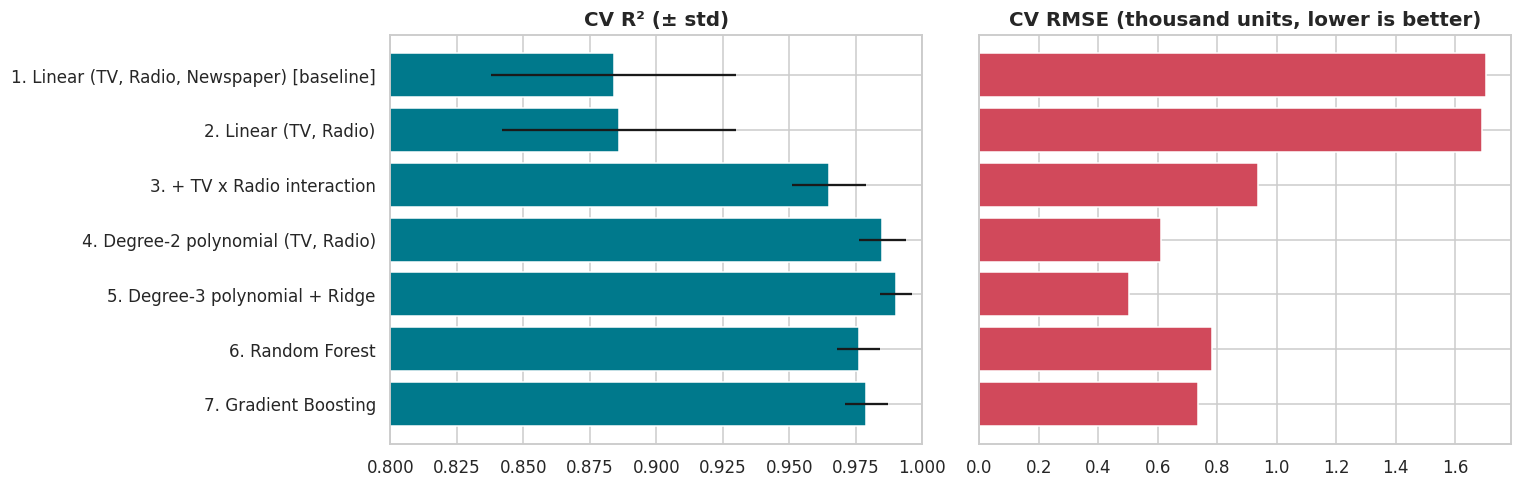

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
o = res.index[::-1]
ax[0].barh(o, res.loc[o, "R2"], xerr=res.loc[o, "R2 std"], color="#00798c"); ax[0].set(title="CV R² (± std)", xlim=(0.8, 1.0))
ax[1].barh(o, res.loc[o, "RMSE"], color="#d1495b"); ax[1].set(title="CV RMSE (thousand units, lower is better)"); ax[1].set_yticklabels([])
plt.tight_layout(); save("05_model_comparison"); plt.show()

In [13]:
# Paired comparison on identical folds: degree-2 (interpretable) vs degree-3 + Ridge (most accurate)
def fold_rmse(est, cols):
    return -cross_validate(est, df[cols], df["Sales"], cv=CV, scoring="neg_root_mean_squared_error", n_jobs=-1)["test_score"]
r2_ = fold_rmse(*spec["4. Degree-2 polynomial (TV, Radio)"]); r3_ = fold_rmse(*spec["5. Degree-3 polynomial + Ridge"])
print(f"Mean RMSE  deg-2: {r2_.mean():.3f}   deg-3+Ridge: {r3_.mean():.3f}")
print(f"Degree-3 has the lower RMSE in {100*np.mean(r3_ < r2_):.0f}% of the 50 folds")

Mean RMSE  deg-2: 0.612   deg-3+Ridge: 0.504
Degree-3 has the lower RMSE in 98% of the 50 folds


**Reading the table**
- Both linear baselines reach R² ≈ 0.88, and adding Newspaper changes nothing (confirming the feature selection).
- Adding the **TV x Radio interaction** lifts R² to 0.965 and nearly halves the error (RMSE 1.70 → 0.94): the channels reinforce each other.
- Adding **curvature** (degree-2 polynomial) reaches R² 0.985 (RMSE 0.61): TV has diminishing returns.
- The **degree-3 polynomial with Ridge** is the most accurate (R² 0.990, MAE 0.34, RMSE 0.50). Ridge regularisation (strength chosen by cross-validation) keeps the extra cubic terms from overfitting.
- Random Forest and Gradient Boosting (R² 0.976 and 0.979) do **not** beat the polynomial models on this small, smooth dataset, and they are less useful for explaining how each channel behaves.

**Which model is final?** The paired comparison shows the degree-3 model has the lower RMSE in nearly every fold (49 of 50), so its advantage is consistent, not noise. It is therefore the **final predictive model**. I keep the degree-2 model alongside it only to read coefficients in plain terms and to check that the business conclusions do not depend on the model choice (section 9).

### Hold-out test

In [14]:
tr, te = train_test_split(df, test_size=0.2, random_state=SEED)
def metrics(y, p): return {"R2": r2_score(y, p), "MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p))}
rows = {}
for name, (est, cols) in spec.items():
    est.fit(tr[cols], tr["Sales"]); rows[name] = metrics(te["Sales"], est.predict(te[cols]))
pd.DataFrame(rows).T.round(3)

,R2,MAE,RMSE
"1. Linear (TV, Radio, Newspaper) [baseline]",0.899,1.461,1.782
"2. Linear (TV, Radio)",0.901,1.444,1.771
3. + TV x Radio interaction,0.974,0.666,0.902
"4. Degree-2 polynomial (TV, Radio)",0.988,0.493,0.603
5. Degree-3 polynomial + Ridge,0.994,0.337,0.424
6. Random Forest,0.980,0.662,0.791
7. Gradient Boosting,0.987,0.545,0.647


On the 40-market hold-out set the final model (degree-3 + Ridge) scores **R² ≈ 0.994, MAE ≈ 0.34, RMSE ≈ 0.42** (thousand units), versus R² ≈ 0.90 and RMSE ≈ 1.78 for the linear baseline. The ranking of models matches the cross-validation. Because the test set is only 40 rows, the repeated-CV numbers are the more reliable estimate.

## 7. Final model and statistical inference

In [15]:
FEATS = ["TV", "Radio"]
final = poly3().fit(df[FEATS], df["Sales"])          # FINAL predictive model: degree-3 polynomial + Ridge (fit on all 200 markets)
final_p2 = poly2().fit(df[FEATS], df["Sales"])       # simpler degree-2 version, used for transparent coefficients and cross-checks

# Degree-2 terms in statsmodels, with heteroscedasticity-robust (HC3) standard errors, to read the effects in plain terms
ols = smf.ols("Sales ~ TV + I(TV**2) + Radio + I(Radio**2) + TV:Radio", df).fit(cov_type="HC3")
tab = ols.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|", "[0.025", "0.975]"]].round(5)
display(tab)
print(f"R² = {ols.rsquared:.4f}   adj. R² = {ols.rsquared_adj:.4f}")

,Coef.,Std.Err.,P>|z|,[0.025,0.975]
Intercept,5.19444,0.24980,0.00000,4.70484,5.68404
TV,0.05099,0.00335,0.00000,0.04442,0.05756
I(TV ** 2),-0.00011,0.00001,0.00000,-0.00013,-0.00009
Radio,0.02654,0.01174,0.02384,0.00352,0.04956
I(Radio ** 2),0.00019,0.00020,0.34272,-0.00020,0.00057
TV:Radio,0.00107,0.00005,0.00000,0.00098,0.00117


R² = 0.9860   adj. R² = 0.9857


Reading the degree-2 coefficients (robust standard errors):
- **TV²** is negative and highly significant: each extra TV dollar adds less than the previous one (**diminishing returns**).
- **TV x Radio** is positive and highly significant: TV works better when radio spend is also high (**synergy**).
- **Radio²** is not significant (p ≈ 0.34), so there is no clear sign of radio saturating within the observed range.
- Individual coefficients are hard to read on their own because these terms are correlated; the marginal effects in section 9 are the clearer way to read the model.

## 8. Diagnostics

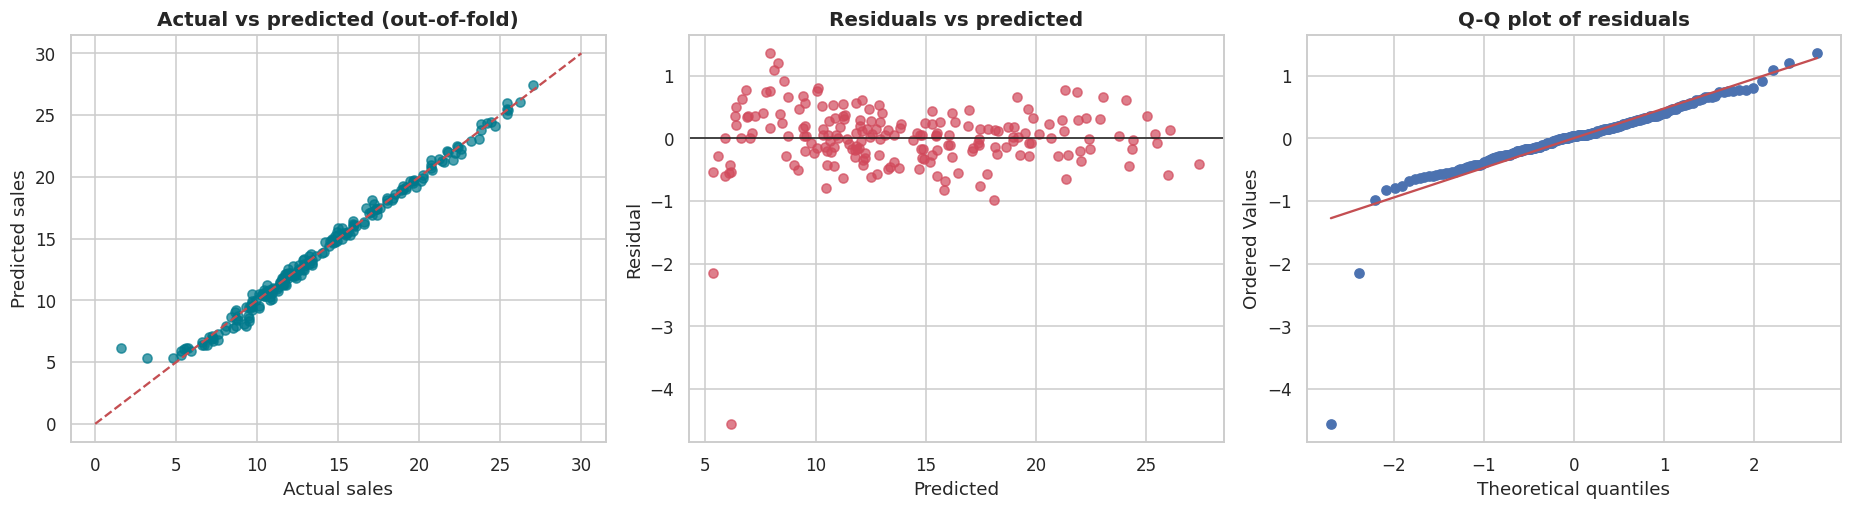

Breusch-Pagan p-value (constant variance): 0.0013
Shapiro-Wilk p-value (normal residuals):   0.0


,TV,Radio,Newspaper,Sales,Predicted,Residual,Cooks
130,0.7,39.6,8.7,1.6,6.16,-4.56,0.742
155,4.1,11.6,5.7,3.2,5.34,-2.14,0.167
78,5.4,29.9,9.4,5.3,5.90,-0.60,0.034
8,8.6,2.1,1.0,4.8,5.34,-0.54,0.033
56,7.3,28.1,41.4,5.5,6.05,-0.55,0.026


In [16]:
oof = cross_val_predict(poly3(), df[FEATS], df["Sales"], cv=KFold(5, shuffle=True, random_state=SEED))
resid = df["Sales"] - oof
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].scatter(df["Sales"], oof, alpha=.7, color="#00798c"); lim = [0, 30]; ax[0].plot(lim, lim, "r--")
ax[0].set(title="Actual vs predicted (out-of-fold)", xlabel="Actual sales", ylabel="Predicted sales")
ax[1].scatter(oof, resid, alpha=.7, color="#d1495b"); ax[1].axhline(0, color="k", lw=1)
ax[1].set(title="Residuals vs predicted", xlabel="Predicted", ylabel="Residual")
stats.probplot(resid, dist="norm", plot=ax[2]); ax[2].set_title("Q-Q plot of residuals")
plt.tight_layout(); save("06_diagnostics"); plt.show()

ols_plain = smf.ols("Sales ~ TV + I(TV**2) + Radio + I(Radio**2) + TV:Radio", df).fit()
print("Breusch-Pagan p-value (constant variance):", round(het_breuschpagan(ols_plain.resid, ols_plain.model.exog)[1], 4))
print("Shapiro-Wilk p-value (normal residuals):  ", round(stats.shapiro(ols_plain.resid)[1], 4))
cook = OLSInfluence(ols_plain).cooks_distance[0]
infl = df.assign(Predicted=oof.round(2), Residual=resid.round(2), Cooks=np.round(cook, 3)).sort_values("Cooks", ascending=False).head(5)
infl

- Predictions track actuals closely and residuals are small and unstructured.
- Two formal tests flag problems: error variance is **not constant** (Breusch-Pagan p ≈ 0.001) and residuals are **not normal** (Shapiro-Wilk). Both are driven by a few unusual markets.
- Market **#130** (TV spend 0.7, radio 39.6, yet sales only 1.6) is by far the most influential point (Cook's distance 0.74) and looks like a possible data anomaly; market #155 is a smaller miss. I keep them, since there is no evidence they are errors, but check the effect below.
- Because of this, I use **robust (HC3) standard errors** for the coefficient table and **empirical residual quantiles** (not a normal assumption) for the prediction ranges.

In [17]:
# Sensitivity: refit/evaluate without the most influential market
worst = int(np.argmax(cook))
d2 = df.drop(index=worst)
pd.concat([cv_table({"Final model (all 200 markets)": (poly3(), FEATS)}),
           cv_table({f"Final model (without market #{worst})": (poly3(), FEATS)}, data=d2)])

,R2,R2 std,MAE,RMSE
Final model (all 200 markets),0.990,0.006,0.339,0.504
Final model (without market #130),0.993,0.003,0.310,0.409


## 9. How do changes in advertising affect sales?

### 9.1 Marginal effect: extra sales per extra $1k
Because of the interaction and curvature, the value of an extra dollar **depends on how much is already spent**. I compute the marginal effect numerically from the model at low / median / high spend levels (25th / 50th / 75th percentile).

In [18]:
def marginal(model, tv, radio, channel, h=0.5):
    f = lambda t, r: model.predict(pd.DataFrame({"TV": [t], "Radio": [r]}))[0]
    return (f(tv + h, radio) - f(tv - h, radio)) / (2 * h) if channel == "TV" else (f(tv, radio + h) - f(tv, radio - h)) / (2 * h)

q = df[["TV", "Radio"]].quantile([.25, .5, .75]); lv = ["Low", "Median", "High"]
tvq, rq = q["TV"].values, q["Radio"].values
mt = pd.DataFrame([[marginal(final, t, r, "TV") for t in tvq] for r in rq],
                  index=[f"Radio {l} ({v:.0f})" for l, v in zip(lv, rq)], columns=[f"TV {l} ({v:.0f})" for l, v in zip(lv, tvq)])
mr = pd.DataFrame([[marginal(final, t, r, "Radio") for t in tvq] for r in rq],
                  index=mt.index, columns=mt.columns)
print("Extra sales (thousand units) per extra $1k of TV spend:"); display((mt).round(3))
print("Extra sales (thousand units) per extra $1k of Radio spend:"); display((mr).round(3))

Extra sales (thousand units) per extra $1k of TV spend:


,TV Low (74),TV Median (150),TV High (219)
Radio Low (10),0.047,0.020,0.017
Radio Median (23),0.061,0.033,0.029
Radio High (37),0.077,0.047,0.042


Extra sales (thousand units) per extra $1k of Radio spend:


,TV Low (74),TV Median (150),TV High (219)
Radio Low (10),0.120,0.202,0.271
Radio Median (23),0.116,0.198,0.267
Radio High (37),0.126,0.208,0.276


- **TV:** an extra $1k of TV adds only about **0.02–0.08 thousand units**. Its value **falls as TV spend rises** (diminishing returns) and **rises with radio spend** (synergy).
- **Radio:** an extra $1k of radio adds about **0.12–0.28 thousand units**, and its value **rises with TV spend**.
- Even the weakest radio cell (0.116) is higher than the strongest TV cell (0.077): in this data, **a marginal dollar is worth much more on radio than on TV** across the whole observed range.
- Neither channel works in isolation: the best returns come when both are present.

### 9.2 Response surface

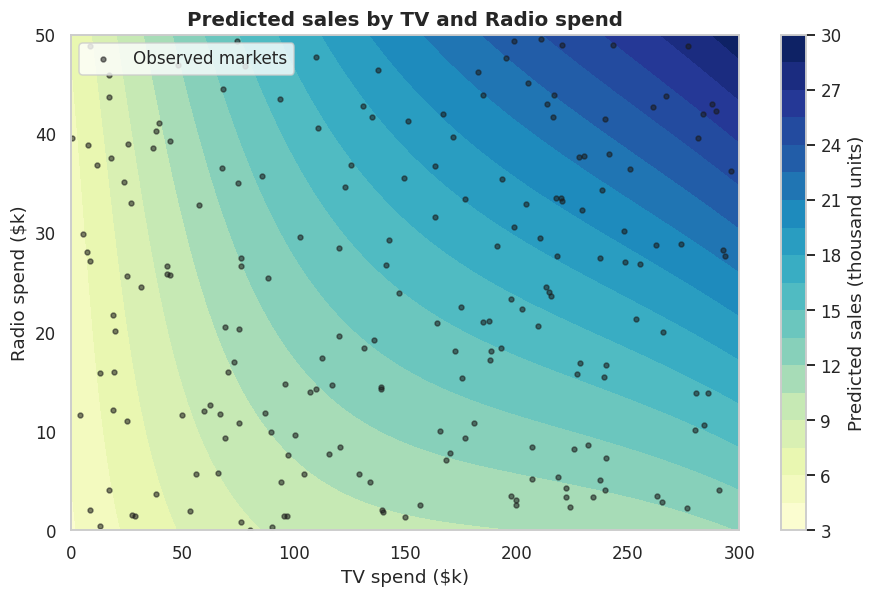

In [19]:
tv_g, ra_g = np.meshgrid(np.linspace(0, 300, 120), np.linspace(0, 50, 100))
Z = final.predict(pd.DataFrame({"TV": tv_g.ravel(), "Radio": ra_g.ravel()})).reshape(tv_g.shape)
fig, ax = plt.subplots(figsize=(8.5, 5.6))
cs = ax.contourf(tv_g, ra_g, Z, levels=18, cmap="YlGnBu"); plt.colorbar(cs, label="Predicted sales (thousand units)")
ax.scatter(df.TV, df.Radio, c="k", s=10, alpha=.55, label="Observed markets")
ax.set(title="Predicted sales by TV and Radio spend", xlabel="TV spend ($k)", ylabel="Radio spend ($k)"); ax.legend(loc="upper left")
plt.tight_layout(); save("07_response_surface"); plt.show()

The observed markets cover the TV x Radio plane fairly evenly (the two are barely correlated), so the surface is supported by data across most of its range, which makes the interaction well estimated. Predictions outside the observed ranges (TV > 296, Radio > 50) should not be trusted.

### 9.3 What-if scenarios (starting from an average market)

In [20]:
base_row = pd.DataFrame({"TV": [df.TV.mean()], "Radio": [df.Radio.mean()]})
base = final.predict(base_row)[0]
sc = {}
for label, dt, dr in [("+ $10k TV", 10, 0), ("+ $10k Radio", 0, 10), ("+ $10k TV and + $10k Radio", 10, 10)]:
    new = pd.DataFrame({"TV": [df.TV.mean() + dt], "Radio": [df.Radio.mean() + dr]})
    sc[label] = {"Spend added ($k)": dt + dr, "Sales change (k units)": final.predict(new)[0] - base}
sc = pd.DataFrame(sc).T
sc["Per $1k spent"] = sc["Sales change (k units)"] / sc["Spend added ($k)"]
print(f"Average market: TV={df.TV.mean():.0f}, Radio={df.Radio.mean():.1f}, predicted sales={base:.2f}k units")
sc.round(3)

Average market: TV=147, Radio=23.3, predicted sales=14.77k units


,Spend added ($k),Sales change (k units),Per $1k spent
+ $10k TV,10.0,0.333,0.033
+ $10k Radio,10.0,1.978,0.198
+ $10k TV and + $10k Radio,20.0,2.413,0.121


From an average market, **$10k more on radio adds about 2.0 thousand units, while $10k more on TV adds only about 0.3 thousand**, so radio is roughly 6x more productive per dollar at this point. Adding both together gives about +2.4 thousand units (a small synergy bonus over the sum of the two parts).

### 9.4 Budget allocation
Given a fixed **TV + Radio budget**, which split does the model predict is best? I search all splits within the observed spend ranges (TV ≤ 296.4, Radio ≤ 49.6) and compare with a "typical" split that keeps the dataset's average TV:Radio proportion.

In [21]:
TVMAX, RMAX = df.TV.max(), df.Radio.max()
TV_SHARE = df.TV.mean() / (df.TV.mean() + df.Radio.mean())

def best_split(model, budget, step=0.25):
    lo, hi = max(0.0, budget - TVMAX), min(RMAX, budget)
    if hi < lo: return None
    r = np.arange(lo, hi + 1e-9, step); t = budget - r
    p = model.predict(pd.DataFrame({"TV": t, "Radio": r}))
    i = int(np.argmax(p)); return t[i], r[i], p[i]

def typical(model, budget):
    t = budget * TV_SHARE; r = budget - t
    return t, r, model.predict(pd.DataFrame({"TV": [t], "Radio": [r]}))[0]

rows = []
for B in [50, 100, 150, 200, 250, 300]:
    bt, br, bp = best_split(final, B); tt, tr_, tp = typical(final, B)
    rows.append({"Budget ($k)": B, "Best TV": bt, "Best Radio": br, "Radio share %": 100 * br / B, "Sales (best)": bp,
                 "Typical TV": tt, "Typical Radio": tr_, "Sales (typical)": tp, "Gain (k units)": bp - tp})
alloc = pd.DataFrame(rows).set_index("Budget ($k)").round(2); alloc

,Best TV,Best Radio,Radio share %,Sales (best),Typical TV,Typical Radio,Sales (typical),Gain (k units)
Budget ($k),,,,,,,,
50,36.5,13.5,27.00,7.95,43.17,6.83,7.87,0.08
100,50.5,49.5,49.50,12.43,86.34,13.66,10.87,1.56
150,100.5,49.5,33.00,16.99,129.51,20.49,13.64,3.35
200,150.5,49.5,24.75,20.41,172.68,27.32,16.49,3.92
250,200.5,49.5,19.80,23.23,215.85,34.15,19.74,3.49
300,250.4,49.6,16.53,26.02,259.02,40.98,23.72,2.30


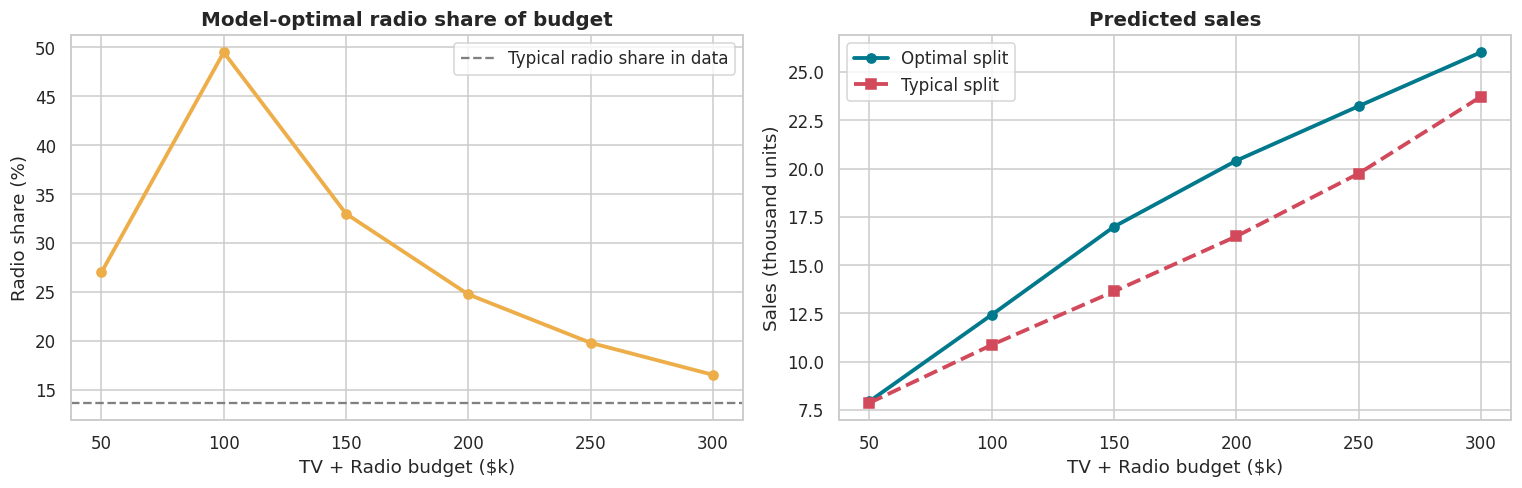

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ax[0].plot(alloc.index, alloc["Radio share %"], marker="o", color="#edae49", lw=2.5)
ax[0].axhline(100 * (1 - TV_SHARE), color="grey", ls="--", label="Typical radio share in data"); ax[0].legend()
ax[0].set(title="Model-optimal radio share of budget", xlabel="TV + Radio budget ($k)", ylabel="Radio share (%)")
ax[1].plot(alloc.index, alloc["Sales (best)"], marker="o", color="#00798c", lw=2.5, label="Optimal split")
ax[1].plot(alloc.index, alloc["Sales (typical)"], marker="s", color="#d1495b", lw=2.5, ls="--", label="Typical split")
ax[1].set(title="Predicted sales", xlabel="TV + Radio budget ($k)", ylabel="Sales (thousand units)"); ax[1].legend()
plt.tight_layout(); save("08_budget_allocation"); plt.show()

**How sure are we?** A point estimate from a fitted model can look more precise than it is, so I bootstrap: refit the model on 300 resampled datasets and check (a) the per-dollar effect of each channel at an average market, (b) the gain of the optimal plan at a $150k budget, and (c) how often the optimal plan sits at the radio spend limit seen in the data.

At an average market:
  TV    marginal effect per $1k: median 0.034 (90% interval 0.032 - 0.036)
  Radio marginal effect per $1k: median 0.195 (90% interval 0.187 - 0.205)
  Radio beats TV per dollar in 100% of bootstrap fits
Gain vs typical split at $150k budget: median 3.367 (90% interval 3.111 - 3.665) k units
Optimal plan puts radio at its observed maximum in 100% of fits


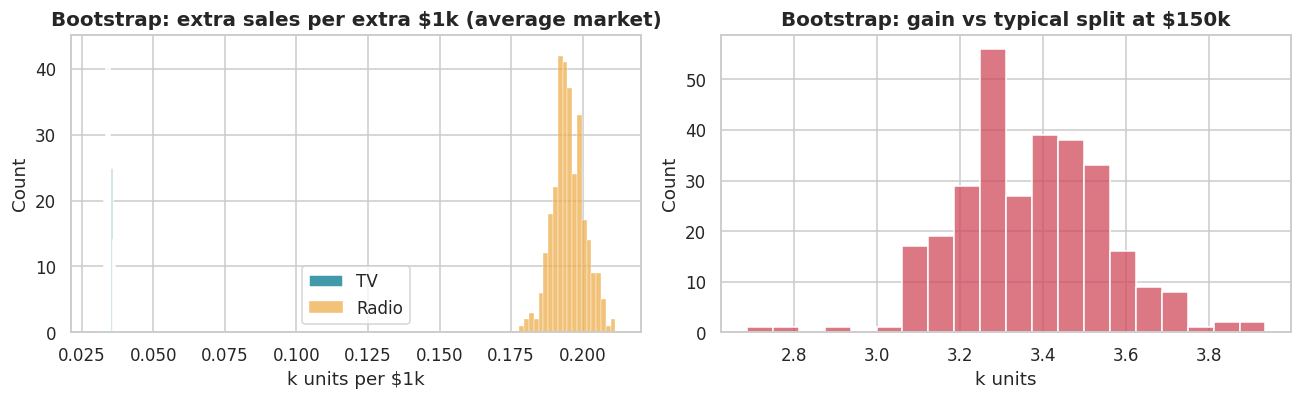

In [23]:
rng = np.random.default_rng(SEED); B = 150
avg = (df.TV.mean(), df.Radio.mean()); tv_m, ra_m, gains, capped = [], [], [], []
for _ in range(300):
    s_ = df.sample(len(df), replace=True, random_state=int(rng.integers(1e9)))
    m = poly3().fit(s_[FEATS], s_["Sales"])
    tv_m.append(marginal(m, *avg, "TV")); ra_m.append(marginal(m, *avg, "Radio"))
    bt, br, bp = best_split(m, B, step=0.5); tt, tr_, tp = typical(m, B)
    gains.append(bp - tp); capped.append(br >= RMAX - 0.6)
tv_m, ra_m, gains = np.array(tv_m), np.array(ra_m), np.array(gains)
ci = lambda a: f"median {np.median(a):.3f} (90% interval {np.percentile(a,5):.3f} - {np.percentile(a,95):.3f})"
print("At an average market:")
print("  TV    marginal effect per $1k:", ci(tv_m))
print("  Radio marginal effect per $1k:", ci(ra_m))
print(f"  Radio beats TV per dollar in {100*np.mean(ra_m > tv_m):.0f}% of bootstrap fits")
print(f"Gain vs typical split at ${B}k budget:", ci(gains), "k units")
print(f"Optimal plan puts radio at its observed maximum in {100*np.mean(capped):.0f}% of fits")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(tv_m, bins=20, ax=ax[0], color="#00798c", label="TV"); sns.histplot(ra_m, bins=20, ax=ax[0], color="#edae49", label="Radio")
ax[0].set(title="Bootstrap: extra sales per extra $1k (average market)", xlabel="k units per $1k"); ax[0].legend()
sns.histplot(gains, bins=20, ax=ax[1], color="#d1495b"); ax[1].set(title=f"Bootstrap: gain vs typical split at ${B}k", xlabel="k units")
plt.tight_layout(); save("09_bootstrap"); plt.show()

In [24]:
# Do the business conclusions depend on the model choice? Compare the final model with the simpler degree-2 model.
chk = {}
for name, m in {"Degree-3 + Ridge (final)": final, "Degree-2 polynomial": final_p2}.items():
    bt, br, bp = best_split(m, 150); tt, tr_, tp = typical(m, 150)
    chk[name] = {"TV marginal (avg market)": marginal(m, *avg, "TV"), "Radio marginal (avg market)": marginal(m, *avg, "Radio"),
                 "Optimal radio at $150k": br, "Sales optimal": bp, "Sales typical": tp}
pd.DataFrame(chk).T.round(3)

,TV marginal (avg market),Radio marginal (avg market),Optimal radio at $150k,Sales optimal,Sales typical
Degree-3 + Ridge (final),0.034,0.195,49.5,16.994,13.64
Degree-2 polynomial,0.044,0.193,49.5,16.326,13.43


**What the allocation analysis says**
- For any budget of $100k or more, the best plan puts radio at the **maximum level seen in the data (≈ $49.5k)** and the rest in TV. At a $50k budget the best split is about 27% radio.
- At a $150k budget, that plan is predicted to sell about **17.0 thousand units versus 13.6** for the typical split, around **+25%**. The gain is largest at mid-range budgets (about +3.9k at $200k) and shrinks at the extremes.
- The bootstrap strongly supports the *direction*: radio beats TV per dollar in **all 300 refits** (about 0.195 vs 0.034 thousand units per $1k at an average market), and the gain at $150k stays within roughly 3.1–3.7 thousand units.
- The degree-2 model gives almost the same radio value (0.193) and the same plan, so the conclusion is not an artefact of the final model choice.

**Important cautions**
1. The optimum sits **at the edge of the data** (radio at its maximum in every refit). The model is telling us "more radio is better throughout the range we observed", not what happens beyond ~$50k radio, where saturation is likely. Do not extrapolate further.
2. The bootstrap only measures sampling uncertainty. It does not cover model misspecification, and the markets were **not randomised**, so these are associations, not proven causal effects. A small controlled test (e.g. shift budget to radio in a few markets) should confirm this before a large reallocation.
3. "Per dollar" assumes a dollar buys comparable reach on each channel, and sales are the only goal (brand, reach and other aims are ignored).

## 10. Save the model and predict for a new plan

In [25]:
log_err = (df["Sales"] - oof).values
q05, q95 = np.quantile(log_err, [0.05, 0.95])
joblib.dump(final, "sales_model.joblib")

def predict_sales(tv, radio):
    p = float(final.predict(pd.DataFrame({"TV": [tv], "Radio": [radio]}))[0])
    return round(p, 2), (round(p + q05, 2), round(p + q95, 2))

for tv, radio in [(150, 20), (230, 40), (50, 10)]:
    p, (lo, hi) = predict_sales(tv, radio)
    print(f"TV={tv}, Radio={radio}  ->  predicted sales {p}k units (90% range {lo} - {hi})")

TV=150, Radio=20  ->  predicted sales 14.22k units (90% range 13.62 - 14.96)
TV=230, Radio=40  ->  predicted sales 21.99k units (90% range 21.39 - 22.73)
TV=50, Radio=10  ->  predicted sales 8.56k units (90% range 7.96 - 9.3)


## 11. Conclusions

**Final model.** A degree-3 polynomial regression with Ridge regularisation on **TV and Radio spend** (Newspaper excluded).
- Cross-validated (5x10): **R² 0.990, MAE 0.34, RMSE 0.50** thousand units; hold-out R² ≈ 0.994. The linear baseline reaches R² ≈ 0.88.
- Typical 90% prediction range is about ±0.7 thousand units around a forecast.

**What drives sales**
1. **Newspaper adds nothing** once TV and Radio are known (coefficient ≈ 0, p ≈ 0.86; no CV gain). Its raw correlation with sales is explained by its correlation with radio spend.
2. **TV has diminishing returns** and **TV and Radio reinforce each other**; an additive model misses this (R² 0.88 vs 0.99).
3. **Radio delivers far more extra sales per dollar than TV** at current spend levels (about 6x at an average market).

**Business recommendations**
- Do not expect newspaper spend to lift sales on its own; review whether that budget could be shifted.
- Prioritise **radio up to the level seen in the data** and keep a meaningful TV budget, because the two work together.
- Avoid pushing TV spend very high: each extra dollar adds less.
- Test before scaling: pilot the reallocation in a few markets.

**Limitations**
- Only 200 markets and no date column, so this is not a time-series forecast, and seasonality or trends cannot be studied.
- Spend ranges are limited (TV ≤ 296, Radio ≤ 50), so predictions outside them are unreliable.
- Observational data: effects are associations, not proven causes.
- Units are assumed ($ thousands, thousand units) as in the standard version of this dataset.
- Task mentions "target segment"; the file has none, so only the three advertising platforms are analysed.